<a href="https://colab.research.google.com/github/uhyeon1222-bit/work/blob/main/test_note.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## [Cell 1] 환경 설정 및 깃허브에서 학습된 가중치 자동 다운로드

In [2]:
import os
import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt

# 1. 실행 디바이스 확인
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"실행 환경: {device}")

# 2. 12개 클래스 정의 (학습 시 ImageFolder 알파벳 순서와 동일)
CLASS_NAMES = [
    'battery', 'biological', 'brown-glass', 'cardboard',
    'clothes', 'green-glass', 'metal', 'paper',
    'plastic', 'shoes', 'trash', 'white-glass'
]

# 3. GitHub Releases에서 학습 완료된 가중치 파일 자동 다운로드
# ※ 반드시 본인의 깃허브 아이디와 레포지토리 이름으로 수정하세요!
WEIGHT_PATH = "best_convnext_tiny.pth"
WEIGHT_URL = "https://github.com/uhyeon1222-bit/work/releases/download/v1.0/best_convnext_tiny.pth"

if not os.path.exists(WEIGHT_PATH):
    print("깃허브에서 학습된 모델 가중치를 다운로드 중입니다...")
    exit_code = os.system(f"wget -q {WEIGHT_URL} -O {WEIGHT_PATH}")
    if exit_code == 0 and os.path.exists(WEIGHT_PATH) and os.path.getsize(WEIGHT_PATH) > 0:
        print("가중치 다운로드 완료!")
    else:
        print("다운로드 실패: WEIGHT_URL 주소와 Release 파일 업로드 상태를 확인해 주세요.")

# 4. 모델 아키텍처 로드 및 가중치 적용
def load_model(weight_path):
    model = models.convnext_tiny(weights=None)
    in_features = model.classifier[2].in_features
    model.classifier[2] = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(in_features, len(CLASS_NAMES))
    )
    model.load_state_dict(torch.load(weight_path, map_location=device))
    model.to(device)
    model.eval()
    return model

model = load_model(WEIGHT_PATH)

# 5. 테스트 이미지 전처리
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
print("모델 로드 및 테스트 준비가 완료되었습니다.")

실행 환경: cpu
깃허브에서 학습된 모델 가중치를 다운로드 중입니다...
가중치 다운로드 완료!
모델 로드 및 테스트 준비가 완료되었습니다.


## [Cell 2] 평가 함수 정의 (TTA 적용 및 폴더/단일 이미지 일괄 채점)

In [5]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

def run_evaluation(target_path, show_images=True):
    """
    target_path에 테스트 이미지 폴더 경로 또는 단일 이미지 파일 경로를 입력하면
    Top-1~3 예측 순위와 확률 막대그래프를 이미지와 나란히 출력하고,
    정답 폴더/파일명 구조일 경우 최종 정확도와 혼동 행렬(Confusion Matrix)을 그려줍니다.
    """
    if os.path.isfile(target_path):
        image_files = [target_path]
    else:
        image_files = sorted(
            glob.glob(os.path.join(target_path, "**", "*.jpg"), recursive=True) +
            glob.glob(os.path.join(target_path, "**", "*.png"), recursive=True) +
            glob.glob(os.path.join(target_path, "**", "*.jpeg"), recursive=True) +
            glob.glob(os.path.join(target_path, "**", "*.webp"), recursive=True)
        )

    if not image_files:
        print(f"경로에서 이미지를 찾을 수 없습니다: {target_path}")
        return

    correct = 0
    labeled_count = 0
    y_true = []
    y_pred = []

    for img_file in image_files:
        img = Image.open(img_file).convert("RGB")

        # TTA (원본 + 좌우 반전 예측 평균)
        img_orig = test_transform(img).unsqueeze(0).to(device)
        img_flip = test_transform(img.transpose(Image.FLIP_LEFT_RIGHT)).unsqueeze(0).to(device)

        with torch.no_grad():
            probs = (F.softmax(model(img_orig), dim=1) + F.softmax(model(img_flip), dim=1)) / 2.0
            # Top-3 추출
            top3_probs, top3_indices = torch.topk(probs, 3, dim=1)

        top3_probs = top3_probs.squeeze(0).cpu().numpy() * 100
        top3_labels = [CLASS_NAMES[idx] for idx in top3_indices.squeeze(0).cpu().numpy()]

        pred_label = top3_labels[0]
        confidence = top3_probs[0]
        top3_str = f"1위: {top3_labels[0]}({top3_probs[0]:.1f}%) | 2위: {top3_labels[1]}({top3_probs[1]:.1f}%) | 3위: {top3_labels[2]}({top3_probs[2]:.1f}%)"

        # 폴더명 또는 파일명에서 정답 라벨 자동 인식
        parent_dir = os.path.basename(os.path.dirname(img_file)).lower()
        file_name_lower = os.path.basename(img_file).lower()

        true_label = None
        if parent_dir in CLASS_NAMES:
            true_label = parent_dir
        else:
            for cname in CLASS_NAMES:
                if cname in file_name_lower:
                    true_label = cname
                    break

        if true_label:
            labeled_count += 1
            y_true.append(true_label)
            y_pred.append(pred_label)
            is_correct = (pred_label == true_label)
            if is_correct:
                correct += 1
            result_str = f"[{'O' if is_correct else 'X'}] {os.path.basename(img_file)} (정답: {true_label}) -> {top3_str}"
        else:
            result_str = f"[{os.path.basename(img_file)}] -> {top3_str}"

        print(result_str)

        # 왼쪽: 원본 사진 / 오른쪽: Top-3 예측 확률 가로 막대그래프
        if show_images and len(image_files) <= 30:
            fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.2), gridspec_kw={'width_ratios': [1, 1.3]})

            # 1) 이미지 출력
            axes[0].imshow(img)
            axes[0].axis('off')
            title_color = 'green' if (true_label and pred_label == true_label) else ('red' if true_label else 'blue')
            axes[0].set_title(f"Pred: {pred_label} ({confidence:.1f}%)", color=title_color, fontsize=11, fontweight='bold')

            # 2) Top-3 확률 막대그래프 출력
            y_pos = range(len(top3_labels))
            colors = ['#1f77b4', '#7f9eb2', '#b8c9d4']
            bars = axes[1].barh(y_pos, top3_probs, color=colors, height=0.55)
            axes[1].set_yticks(y_pos)
            axes[1].set_yticklabels([f"#{i+1} {lbl}" for i, lbl in enumerate(top3_labels)], fontsize=10, fontweight='bold')
            axes[1].invert_yaxis()  # 1위가 맨 위로 오도록 반전
            axes[1].set_xlim(0, 115)
            axes[1].set_xlabel("Confidence (%)", fontsize=9)
            axes[1].set_title("Top-3 Prediction Probabilities", fontsize=10)
            axes[1].spines['top'].set_visible(False)
            axes[1].spines['right'].set_visible(False)

            for bar, prob in zip(bars, top3_probs):
                axes[1].text(prob + 2, bar.get_y() + bar.get_height()/2, f"{prob:.1f}%", va='center', fontsize=9.5)

            plt.tight_layout()
            plt.show()

    # 정답 라벨이 포함된 경우: 최종 정확도 + 혼동 행렬 그래프 출력
    if labeled_count > 0:
        acc = 100.0 * correct / labeled_count
        print("\n" + "="*65)
        print(f"총 평가 이미지 수: {labeled_count}장 | 정답: {correct}장 | 최종 정확도: {acc:.2f}%")
        print("="*65)

        present_labels = sorted(list(set(y_true) | set(y_pred)))
        cm = confusion_matrix(y_true, y_pred, labels=present_labels)

        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=present_labels, yticklabels=present_labels)
        plt.title(f"Test Set Confusion Matrix (Accuracy: {acc:.2f}%)", fontsize=13)
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

## [Cell 3] 교수님 실행용 셀 (경로 지정 후 바로 실행)

아래 [파일 선택] 버튼을 눌러 테스트할 쓰레기 이미지를 업로드해 주세요. (여러 장 동시 선택 가능)


Saving 11.jpg to 11.jpg
Saving 333.jpg to 333.jpg
Saving 2222.jpg to 2222.jpg
Saving 4444.jpg to 4444.jpg
Saving 5555.jpg to 5555.jpg

총 5장의 이미지 업로드 완료! 분류를 시작합니다...

[11.jpg] -> 1위: trash(58.0%) | 2위: plastic(16.9%) | 3위: metal(7.1%)


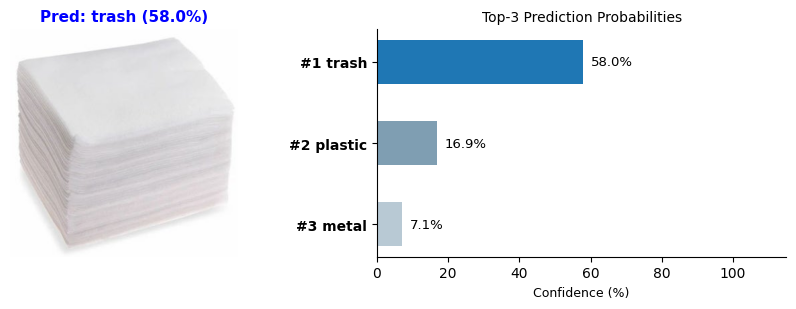

[2222.jpg] -> 1위: green-glass(92.9%) | 2위: plastic(0.8%) | 3위: brown-glass(0.8%)


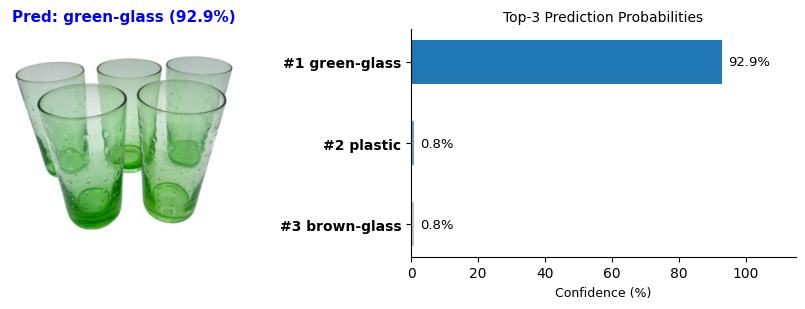

[333.jpg] -> 1위: plastic(29.3%) | 2위: clothes(22.3%) | 3위: paper(13.2%)


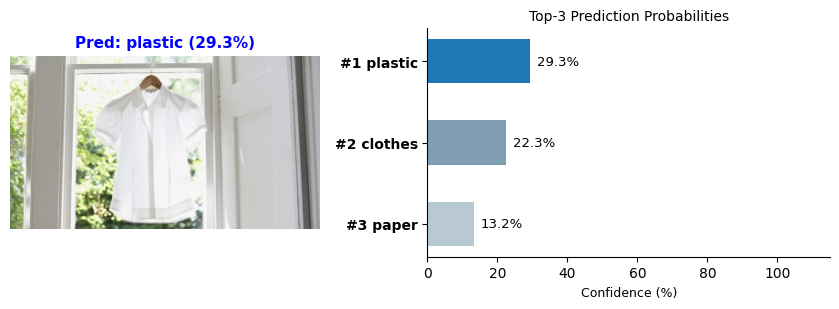

[4444.jpg] -> 1위: shoes(84.6%) | 2위: white-glass(1.9%) | 3위: metal(1.7%)


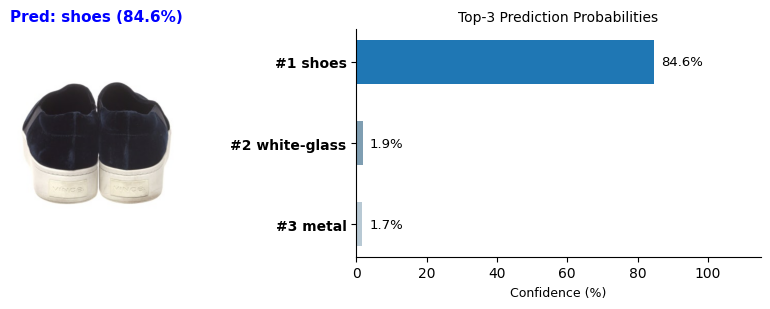

[5555.jpg] -> 1위: battery(91.6%) | 2위: green-glass(1.5%) | 3위: brown-glass(1.1%)


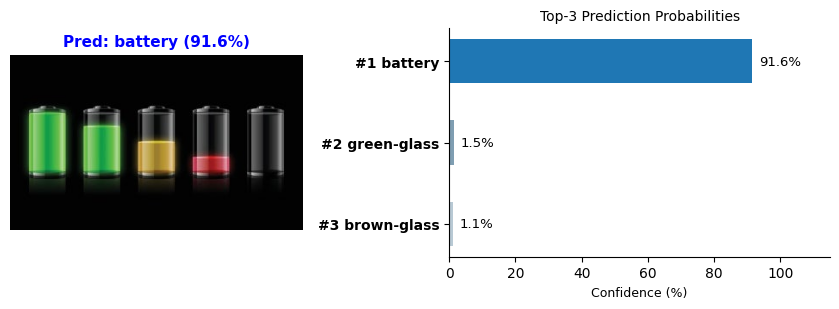

In [6]:
from google.colab import files
import shutil

# 기존에 업로드된 임시 테스트 폴더가 있다면 초기화
upload_dir = "/content/uploaded_test_images"
if os.path.exists(upload_dir):
    shutil.rmtree(upload_dir)
os.makedirs(upload_dir, exist_ok=True)

print("아래 [파일 선택] 버튼을 눌러 테스트할 쓰레기 이미지를 업로드해 주세요. (여러 장 동시 선택 가능)")
uploaded = files.upload()

if not uploaded:
    print("업로드된 파일이 없습니다.")
else:
    for filename in uploaded.keys():
        shutil.move(filename, os.path.join(upload_dir, filename))
    print(f"\n총 {len(uploaded)}장의 이미지 업로드 완료! 분류를 시작합니다...\n")

    # 업로드된 이미지 일괄 평가 실행
    run_evaluation(upload_dir, show_images=True)